In [1]:
import numpy as np
from skimage.measure import marching_cubes
import pyvista as pv
import trimesh


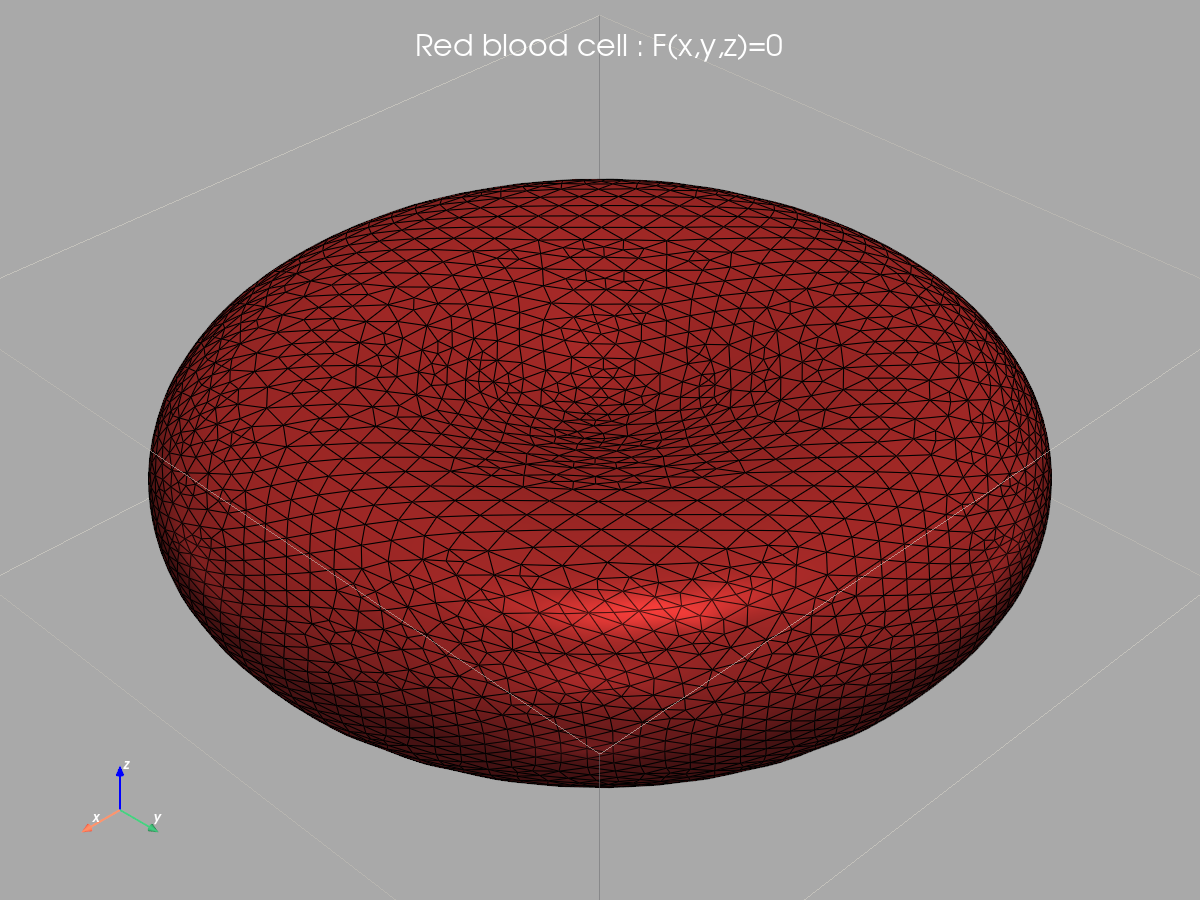

In [2]:
d = 8.0
b = 1.0
h = 2.12

# Domaine 3D
n = 30
xmin, xmax = -d/2, d/2
ymin, ymax = -d/2, d/2
zmin, zmax = -1.5*b, 1.5*b

x = np.linspace(xmin, xmax, n)
y = np.linspace(ymin, ymax, n)
z = np.linspace(zmin, zmax, n)

dx = x[1] - x[0]
dy = y[1] - y[0]
dz = z[1] - z[0]

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

# Fonction implicite
P = -d**2/2 + h**2/2*(d**2/b**2 - 1.0) - h**2/2*(d**2/b**2-1)*np.sqrt(1-b**2/h**2)
Q = P * d**2/b**2 + b**2/4*(d**4/b**4 - 1.0)
R = -P * d**2/4 - d**4/16.0

F = (X**2+Y**2+Z**2)**2 + P*(X**2+Y**2) + Q*Z**2  + R

# Extraction de l'isosurface F=0 par marching cubes
verts, faces, normals, values = marching_cubes(
    F,
    level=0.0,
    spacing=(dx, dy, dz)
)

# Correction du décalage dû au spacing
verts[:, 0] += xmin
verts[:, 1] += ymin
verts[:, 2] += zmin

# Format des faces pour PyVista :
# chaque triangle doit être écrit [3, i, j, k]
faces_pv = np.hstack([
    np.full((faces.shape[0], 1), 3),
    faces
]).astype(np.int64)

mesh = pv.PolyData(verts, faces_pv)

# Calcul des normales pour un rendu plus lisse
mesh = mesh.compute_normals(
    point_normals=True,
    cell_normals=True,
    auto_orient_normals=True
)

# Optionnel : lissage léger
mesh_smooth = mesh.smooth(
    n_iter=100,
    relaxation_factor=0.05,
    feature_smoothing=False,
    boundary_smoothing=True
)

# ============================================================
# Visualisation PyVista
# ============================================================

plotter = pv.Plotter(window_size=(1200, 900))

plotter.set_background("darkgrey")

plotter.add_mesh(
    mesh_smooth,
    color="brown",
    smooth_shading=True,
    specular=0.7,
    specular_power=25,
    ambient=0.05,
    opacity = 1.0,
    show_edges=True
)

# Boîte du domaine
box = pv.Box(bounds=(xmin, xmax, ymin, ymax, zmin, zmax))
plotter.add_mesh(
    box,
    style="wireframe",
    color="white",
    opacity=0.35
)

# Axes
plotter.add_axes(
    xlabel="x",
    ylabel="y",
    zlabel="z",
    line_width=2,
    color="white"
)

plotter.add_title(
    "Red blood cell : F(x,y,z)=0",
    font_size=12,
    color="white"
)

# Caméra
plotter.camera_position = "iso"
plotter.camera.zoom(1.5)

plotter.show(jupyter_backend='static')

In [3]:
mesh = trimesh.Trimesh(vertices=verts, faces=faces)

mesh.export("RBC.obj");

In [4]:
mesh_smooth

PolyData (0x1dab913e2c0)
  N Cells:    7516
  N Points:   3760
  N Strips:   0
  X Bounds:   -3.938e+00, 3.938e+00
  Y Bounds:   -3.938e+00, 3.938e+00
  Z Bounds:   -1.033e+00, 1.033e+00
  N Arrays:   2